In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"/Users/kashvivirmani/Desktop/Delhi_UHI_Project/Data/Processed/cleaned_dataset.csv")
df.head()

,Latitude,Longitude,AirTemp,DistanceToWater,Elevation,Humidity,LST,LULC,MNDWI,NDBI,NDVI,Population,Slope,WindSpeed,LULC_Name
0,28.632720,77.204349,32.490555,1065.082156,223,28.763419,41.820506,6,-0.103358,-0.061668,0.161954,190.287857,3.489779,1.422401,Built Area
1,28.614477,77.114090,32.618237,4417.420062,219,28.276358,46.014417,6,-0.089072,-0.004090,0.071271,318.664734,1.854334,1.422094,Built Area
2,28.783908,77.106962,32.277801,56.568542,211,29.923939,44.336169,0,-0.086957,-0.014011,0.089721,0.000000,1.406886,1.355455,Water
3,28.660692,77.147372,32.479869,1059.056184,216,29.162266,45.623053,6,-0.079266,-0.051205,0.125391,268.919067,2.307262,1.391453,Built Area
4,28.814437,76.991782,32.366906,1223.764683,226,29.204621,50.153639,7,-0.151679,0.025338,0.100419,0.000000,4.263645,1.359317,Bare Ground


In [3]:
cols = ["NDBI", "NDVI", "MNDWI", "LST", "LULC_Name", "Population", "Elevation", "Slope", "AirTemp", "Humidity", "WindSpeed", "DistanceToWater"]
df[cols].describe()

,NDBI,NDVI,MNDWI,LST,Population,Elevation,Slope,AirTemp,Humidity,WindSpeed,DistanceToWater
count,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000,9989.000000
mean,-0.003183,0.124802,-0.144933,46.653446,135.946131,221.726099,3.338974,32.511031,28.734027,1.401367,2272.740961
std,0.045296,0.054655,0.038498,3.392932,201.301024,18.023081,2.389409,0.203881,1.000813,0.033844,1466.707950
min,-0.231094,-0.022731,-0.349778,34.811856,0.000000,193.000000,0.000000,31.983528,26.851850,1.310823,0.000000
25%,-0.033130,0.082297,-0.175179,44.370349,0.000000,212.000000,1.854334,32.366906,27.780962,1.385324,1126.410227
50%,0.005303,0.113899,-0.147289,46.303239,21.889830,216.000000,2.812470,32.509743,28.624378,1.405447,2027.806697
75%,0.029128,0.159670,-0.114896,48.894099,233.239151,222.000000,4.263695,32.641314,29.284862,1.422401,3168.090908
max,0.180714,0.372367,0.084918,56.393234,2473.872559,309.000000,44.616486,32.992381,31.404594,1.488759,8124.235349


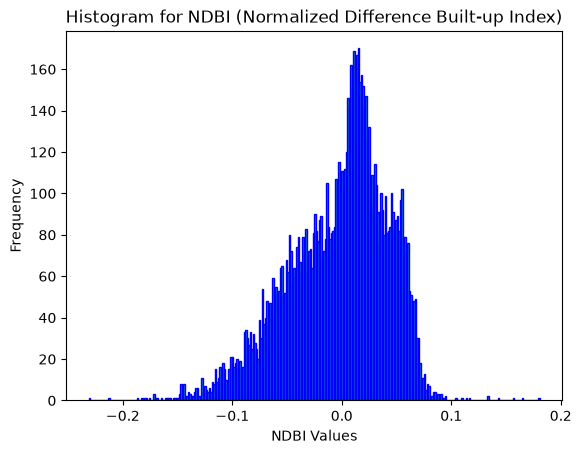

In [4]:
# Histogram for NDBI -> right skewed
ndbi_series = df["NDBI"]
plt.hist(ndbi_series, bins=300, edgecolor="blue")
plt.xlabel("NDBI Values")
plt.ylabel("Frequency")
plt.title("Histogram for NDBI (Normalized Difference Built-up Index)")
plt.show()

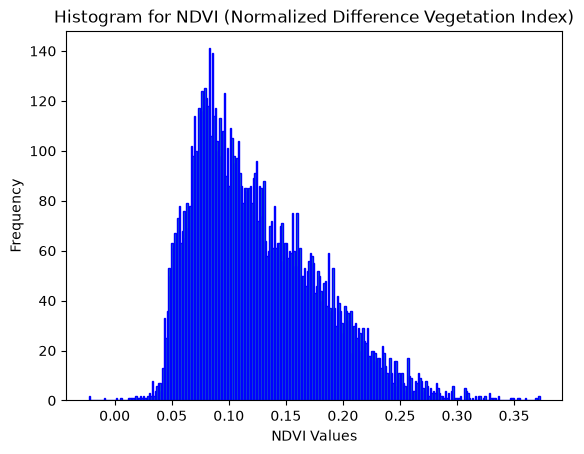

In [5]:
# Histogram for NDVI -> left skewed
ndvi_series = df["NDVI"]
plt.hist(ndvi_series, bins=300, edgecolor="blue")
plt.xlabel("NDVI Values")
plt.ylabel("Frequency")
plt.title("Histogram for NDVI (Normalized Difference Vegetation Index)")
plt.show()

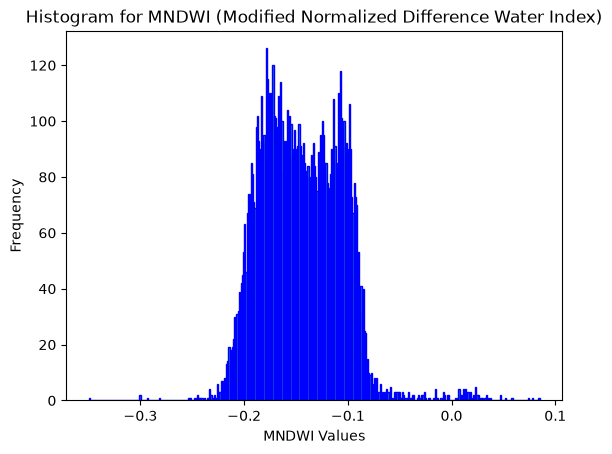

In [6]:
# Histogram for MNDWI 
mndwi_series = df["MNDWI"]
plt.hist(mndwi_series, bins=400, edgecolor="blue")
plt.xlabel("MNDWI Values")
plt.ylabel("Frequency")
plt.title("Histogram for MNDWI (Modified Normalized Difference Water Index)")
plt.show()

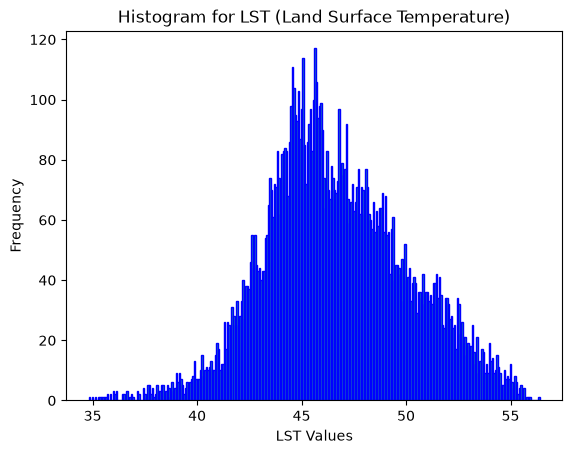

In [7]:
# Histogram LST
plt.hist(df["LST"], bins=300, edgecolor="blue")
plt.title("Histogram for LST (Land Surface Temperature)")
plt.xlabel("LST Values")
plt.ylabel("Frequency")
plt.show()

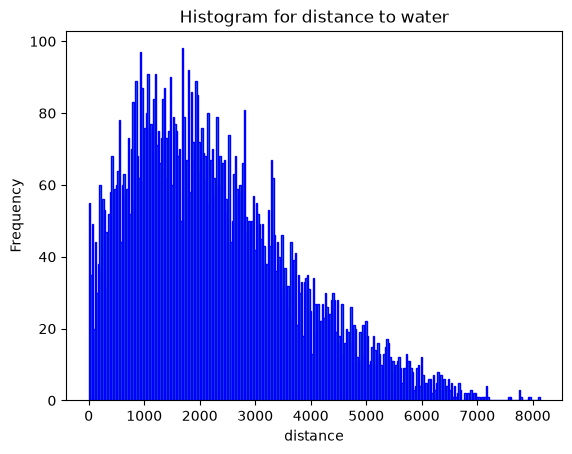

In [8]:
# Histogram Population
plt.hist(df["DistanceToWater"], bins=300, edgecolor="blue")
plt.title("Histogram for distance to water")
plt.xlabel("distance")
plt.ylabel("Frequency")
plt.show()

In [9]:
df["LST"].describe()

count    9989.000000
mean       46.653446
std         3.392932
min        34.811856
25%        44.370349
50%        46.303239
75%        48.894099
max        56.393234
Name: LST, dtype: float64

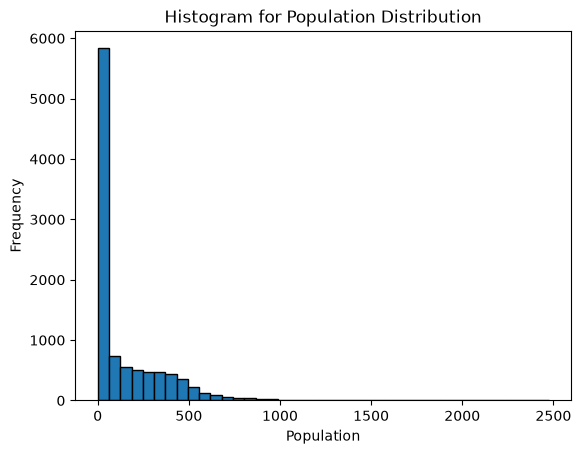

In [10]:
# Population Distribution
plt.hist(df["Population"], bins=40, edgecolor="black")
plt.xlabel("Population")
plt.ylabel("Frequency")
plt.title("Histogram for Population Distribution")
plt.show()

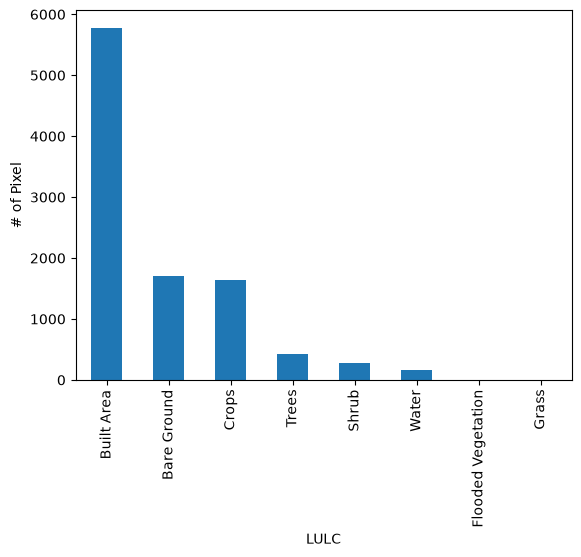

In [11]:
# Distribution for LULC
# plt.hist(df["LULC"], bins=30, edgecolor="black")
df["LULC_Name"].value_counts().plot(kind="bar")
plt.xlabel("LULC")
plt.ylabel("# of Pixel")
plt.xticks(rotation=90)
plt.show()

In [12]:
df_numeric = df.select_dtypes(include=np.number)
df_numeric.drop(["Latitude","Longitude"],axis=1)
corr = df_numeric.corr()

In [13]:
corr

,Latitude,Longitude,AirTemp,DistanceToWater,Elevation,Humidity,LST,LULC,MNDWI,NDBI,NDVI,Population,Slope,WindSpeed
Latitude,1.000000,-0.102147,-0.669104,-0.292444,-0.567653,0.771249,0.059016,0.042108,0.143015,0.076252,-0.182831,-0.004423,-0.047404,-0.940430
Longitude,-0.102147,1.000000,-0.581033,0.104387,0.164841,0.485678,-0.575342,-0.053684,0.413602,-0.411525,0.181212,0.356969,0.041092,0.088330
AirTemp,-0.669104,-0.581033,1.000000,0.094271,0.169205,-0.953395,0.298838,0.020080,-0.305697,0.185948,-0.002124,-0.164256,-0.000860,0.684423
DistanceToWater,-0.292444,0.104387,0.094271,1.000000,0.349887,-0.180098,0.070683,0.079476,-0.136238,0.043591,0.050045,0.019789,0.001705,0.269815
Elevation,-0.567653,0.164841,0.169205,0.349887,1.000000,-0.379586,-0.068713,-0.106926,-0.228553,0.005601,0.170626,-0.101900,0.086050,0.598518
Humidity,0.771249,0.485678,-0.953395,-0.180098,-0.379586,1.000000,-0.265986,0.004348,0.346909,-0.159126,-0.057376,0.191287,-0.021898,-0.800582
LST,0.059016,-0.575342,0.298838,0.070683,-0.068713,-0.265986,1.000000,0.270912,-0.557953,0.755858,-0.443553,-0.256904,-0.036180,-0.107204
LULC,0.042108,-0.053684,0.020080,0.079476,-0.106926,0.004348,0.270912,1.000000,0.001870,0.240410,-0.287469,0.284639,-0.053594,-0.042864
MNDWI,0.143015,0.413602,-0.305697,-0.136238,-0.228553,0.346909,-0.557953,0.001870,1.000000,-0.397523,-0.250842,0.538096,0.001651,-0.113753
NDBI,0.076252,-0.411525,0.185948,0.043591,0.005601,-0.159126,0.755858,0.240410,-0.397523,1.000000,-0.778737,-0.058978,-0.051769,-0.102944


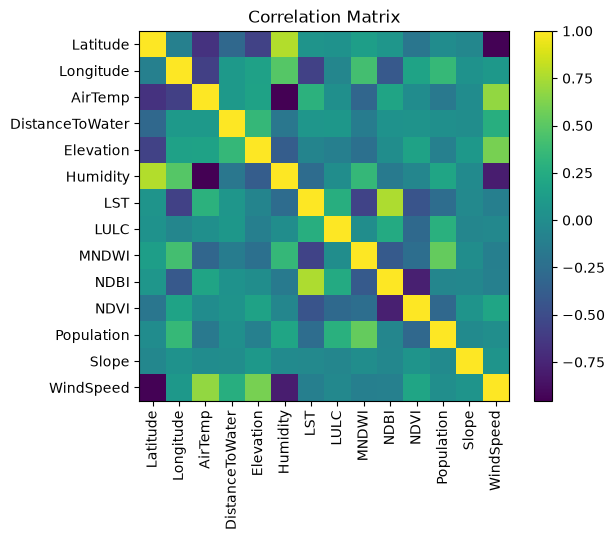

In [14]:
plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.show()

In [15]:
features = ["LULC","MNDWI","NDBI","NDVI","Population","AirTemp","Elevation","Humidity","WindSpeed"]
df_numeric[features].corrwith(df_numeric["LST"])

LULC          0.270912
MNDWI        -0.557953
NDBI          0.755858
NDVI         -0.443553
Population   -0.256904
AirTemp       0.298838
Elevation    -0.068713
Humidity     -0.265986
WindSpeed    -0.107204
dtype: float64

In [16]:
df.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'LST', 'LULC', 'MNDWI', 'NDBI', 'NDVI', 'Population',
       'Slope', 'WindSpeed', 'LULC_Name'],
      dtype='str')